# Practical 1 report: preparing biological data for machine learning

**Student:** Alina Kharchenko
**Date:** 12-10-26  
**Practical:** 1 - Data to ML-ready format

## 2. Data-preparation readiness

Complete this section before describing modelling results.

## Scientific purpose and provenance

- [ y] Is the biological question and prediction task stated clearly?
- [ y] Is the unit of observation clear (for example, patient, tissue, cell, mouse, or technical measurement)?
- [ y] Have I recorded the data version, processing history, and transformations already applied?

Notes
- Question: predict Genotype (Control vs Ts65Dn trisomy) of new, unseen mice from protein expression.
- Unit of observation: one row = one technical measurement (an RPPA spot at one dilution point). The independent biological unit is the mouse (72 mice x 15 rows = 1,080 rows).
- Data/processing: UCI Mice Protein Expression (dataset 342), file Data_Cortex_Nuclear.xls, used exactly as distributed. No additional normalization or transformation was applied by me; standardization happens only inside the visualization PCA and inside the optional logistic-regression pipeline. Processing steps carried out by the source are not documented in the file.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn, scipy
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, cross_val_score
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from scipy.stats import fisher_exact

DATA = Path(".")
FILE = "Data_Cortex_Nuclear.xls"
RANDOM_STATE = 100926

mice = pd.read_excel("Data_Cortex_Nuclear.xls")
print("Loaded:", FILE, "| shape:", mice.shape)

Loaded: Data_Cortex_Nuclear.xls | shape: (1080, 82)


## Table shape and identifiers

- [ y] Is the table tidy: one observation per row, one variable per column, and one value per cell?
- [ y] If the original assay has features in rows and samples in columns, have I transposed it into the format expected by the analysis tool?
- [ y] Are row names, column names, and identifiers clear, unique, stable, and free from accidental index columns?
- [ y] Can every feature and observation be traced back to its source?
- [y ] Are the feature matrix and metadata aligned by an explicit identifier rather than by row order?

- The table is already in samples-x-features orientation, so no transposition was needed.
- It is tidy at the level of the *measurement* (one row per technical measurement, one value per cell), with two exceptions that I handle explicitly: `MouseID` packs *mouse* and *record number* into one string (`309_1`), so I derive `mouse_id`; and `class` packs genotype, behavior and treatment into one label, so it is treated as a derived/composite column, not an independent variable. Mouse-level metadata are repeated on each of the 15 rows of a mouse.
- There is a single table, so metadata/feature alignment by row order is not an issue.

In [3]:
meta_cols = ["MouseID", "Genotype", "Treatment", "Behavior", "class"]
protein_cols = [c for c in mice.columns if c not in meta_cols]
mice["mouse_id"] = mice["MouseID"].astype(str).str.rsplit("_", n=1).str[0]

print("Protein columns:", len(protein_cols))
print("MouseID unique:", mice["MouseID"].is_unique)
print("Rows:", len(mice), "| unique mice:", mice["mouse_id"].nunique())
print("Columns (first/last):", mice.columns.tolist()[:3], "...", mice.columns.tolist()[-6:])
mice[["MouseID", "mouse_id", "Genotype", "Treatment", "Behavior", "class"]].head()

Protein columns: 77
MouseID unique: True
Rows: 1080 | unique mice: 72
Columns (first/last): ['MouseID', 'DYRK1A_N', 'ITSN1_N'] ... ['CaNA_N', 'Genotype', 'Treatment', 'Behavior', 'class', 'mouse_id']


,MouseID,mouse_id,Genotype,Treatment,Behavior,class
0,309_1,309,Control,Memantine,C/S,c-CS-m
1,309_2,309,Control,Memantine,C/S,c-CS-m
2,309_3,309,Control,Memantine,C/S,c-CS-m
3,309_4,309,Control,Memantine,C/S,c-CS-m
4,309_5,309,Control,Memantine,C/S,c-CS-m


## Types, values, and measurement meaning

- [y ] Are numerical, categorical, ordinal, text, date, and identifier columns correctly classified?
- [ ] Are units, scales, encodings, reference categories, and detection limits understood?
- [ y] Have I checked impossible values, inconsistent labels, unexpected categories, constant features, and extreme values?
- [ ] Are normalization, scaling, log transformation, and batch-correction steps documented?

- 77 protein columns are `float64`; `MouseID`, `Genotype`, `Treatment`, `Behavior`, `class` are categorical/identifier strings; `mouse_id` is a derived string identifier.
- Not fully satisfied (left unticked): the file does not document **units, scales or detection limits** (values are continuous, range -0.062 to 8.483), and the **normalization/batch-correction** history of the source data is not documented; I did not apply any myself.
- Checks for impossible values, labels, constant features and extremes are in section 3.3.

In [4]:
print(mice[protein_cols].dtypes.value_counts())
print("All protein columns numeric:", all(pd.api.types.is_numeric_dtype(mice[c]) for c in protein_cols))
for col in ["Genotype", "Treatment", "Behavior", "class"]:
    print(col, "->", sorted(mice[col].dropna().unique()))

float64    77
Name: count, dtype: int64
All protein columns numeric: True
Genotype -> ['Control', 'Ts65Dn']
Treatment -> ['Memantine', 'Saline']
Behavior -> ['C/S', 'S/C']
class -> ['c-CS-m', 'c-CS-s', 'c-SC-m', 'c-SC-s', 't-CS-m', 't-CS-s', 't-SC-m', 't-SC-s']


## Missing values

- [y ] Have I detected missing values using the dataset's actual missing-value representations, not only `NaN`?
- [y ] Have I measured missingness by row, column, group, and relevant batch or time variable?
- [ y] Do I know whether missingness is structural, technical, or plausibly related to the biology or target?
- [ y] Have I justified whether to retain, remove, or impute missing values?
- [ y] If imputing, will the imputer be fitted on training data only and then applied to validation/test data?

- Missing values are only `NaN` in protein columns (1,396 cells = 1.68%; 49 of 77 proteins affected); metadata have none. No other missing-value codes occur: all 77 protein columns are numeric.
- Missingness was examined by column, by row, and by group (Genotype, Treatment, Behavior). There is no batch or time variable in the file.
- It is **structural at mouse level**: counts are (almost exactly) multiples of 15, e.g. `BCL2_N` 285 = 19 mice x 15 rows, so whole mice lack a protein. It is also **related to the target**: `H3MeK4_N` is missing in 34% of Control rows vs 15% of Ts65Dn; `BAD_N` 24% vs 15%.
- Decision: drop the 6 proteins with >5% missing (determined on training data only), impute the few remaining sporadic gaps with the training-set median.

In [5]:
na_prot = mice[protein_cols].isna().sum().sort_values(ascending=False)
print("Proteins with any NA:", (na_prot > 0).sum(), "of", len(protein_cols))
print("Total missing protein cells:", int(na_prot.sum()),
      f"({na_prot.sum() / mice[protein_cols].size:.2%})")
print("Rows with at least one NA:", int(mice[protein_cols].isna().any(axis=1).sum()), "of", len(mice))
print("Missing in metadata:\n", mice[meta_cols + ["mouse_id"]].isna().sum())

miss_report = (na_prot.rename("n_missing").to_frame()
               .assign(pct=lambda d: (d.n_missing / len(mice) * 100).round(2)))
miss_report = miss_report[miss_report.n_missing > 0]
print("\nMissingness report (top 10 proteins):")
print(miss_report.head(10))

top = list(miss_report.index[:6])
full_na = mice.groupby("mouse_id")[top].agg(lambda s: s.isna().all())
print("\nMice in which the protein is missing in ALL 15 rows (structural):")
print(full_na.sum())

for g in ["Genotype", "Treatment", "Behavior"]:
    print(f"\nFraction missing by {g}:")
    print(mice.groupby(g)[top].apply(lambda d: d.isna().mean()).round(3))
geno_by_mouse = mice.groupby("mouse_id")["Genotype"].first()
print("\nMice with the protein missing in all rows, by genotype:")
print(full_na.groupby(geno_by_mouse).sum())

Proteins with any NA: 49 of 77
Total missing protein cells: 1396 (1.68%)
Rows with at least one NA: 528 of 1080
Missing in metadata:
 MouseID      0
Genotype     0
Treatment    0
Behavior     0
class        0
mouse_id     0
dtype: int64

Missingness report (top 10 proteins):
            n_missing    pct
BCL2_N            285  26.39
H3MeK4_N          270  25.00
BAD_N             213  19.72
EGR1_N            210  19.44
H3AcK18_N         180  16.67
pCFOS_N            75   6.94
ELK_N              18   1.67
Bcatenin_N         18   1.67
MEK_N               7   0.65
P38_N               3   0.28

Mice in which the protein is missing in ALL 15 rows (structural):
BCL2_N       19
H3MeK4_N     18
BAD_N        14
EGR1_N       14
H3AcK18_N    12
pCFOS_N       5
dtype: int64

Fraction missing by Genotype:
          BCL2_N  H3MeK4_N  BAD_N  EGR1_N  H3AcK18_N  pCFOS_N
Genotype                                                     
Control    0.289     0.342  0.242   0.211      0.184    0.053
Ts65Dn     0

## Replicates, dependence, and grouping

- [ y] Have I checked for exact duplicates and near-duplicate observations?
- [ y] Are observations biological replicates, technical replicates, repeated measurements, pseudo-replicates, or independent samples?
- [ y] Is the independent biological unit identified by a grouping variable?
- [ y] Will all related observations and their derivatives remain in the same train/validation/test split?
- [ y] If I created augmented or synthetic observations, is their provenance recorded and reproducible?

- Exact duplicates: none (no duplicate rows, no duplicate `MouseID`). Near-duplicates are not computed directly; they are handled structurally by grouping and confirmed indirectly in the optional experiment (row-wise accuracy is far higher than mouse-grouped accuracy).
- The 15 rows per mouse are **technical replicates** (5 dilution points x 3 spots) of the same sample, not independent observations. Every mouse has exactly 15 rows.
- The independent unit is the mouse; `mouse_id` is the grouping variable and all 15 rows stay in one partition (verified in 3.5).
- No augmented or synthetic observations were created in this task.

In [7]:
print("Duplicate rows:", mice.duplicated().sum())
print("Duplicate MouseID:", mice["MouseID"].duplicated().sum())
cnt = mice.groupby("mouse_id").size()
print("Mice with != 15 rows:", int((cnt != 15).sum()), "| rows per mouse:", sorted(cnt.unique()))

Duplicate rows: 0
Duplicate MouseID: 0
Mice with != 15 rows: 0 | rows per mouse: [np.int64(15)]


## Target, leakage, and study design

- [y ] Is the target defined before modelling, with its classes or values checked for balance and validity?
- [ y] Have I excluded identifiers, post-outcome variables, duplicated target information, and other leakage sources from the features?
- [ y] Have I identified batch, site, plate, subject, cohort, treatment, sex, age, time, or other possible confounders?
- [ y] Have I checked whether the target is associated with a technical or grouping variable?
- [y ] Does the planned split represent the biological generalization question?

- Target: `Genotype` (Control 570 rows / 38 mice; Ts65Dn 510 rows / 34 mice), roughly balanced and valid (two clean labels).
- Excluded from features: `MouseID`, `mouse_id`, the target, and `class` (it contains genotype); `Treatment` and `Behavior` are also excluded (they would change the question).
- Possible confounders examined: treatment, behavior, composite class, rows per mouse. Batch/day is **not recorded** in the file, so hidden batch effects cannot be excluded.
- Target vs grouping/design variables: Genotype x Treatment p = 1.000 and Genotype x Behavior p = 0.818 (mouse level), no evidence of imbalance.

In [6]:
print(mice["Genotype"].value_counts())
mouse_geno = mice.groupby("mouse_id")["Genotype"].first()
print("\nMice per genotype:\n", mouse_geno.value_counts())

Genotype
Control    570
Ts65Dn     510
Name: count, dtype: int64

Mice per genotype:
 Genotype
Control    38
Ts65Dn     34
Name: count, dtype: int64


## Reproducibility and decision record

- [ y] Are random seeds, software versions, file names, and input/output shapes recorded?
- [ y] Are all preprocessing steps placed in a reproducible pipeline?
- [ y] Have I recorded unresolved data-quality concerns and the decisions made about them?
- [ y] Can another person explain what each row, column, feature, target, and grouping variable means?

- Seed `RANDOM_STATE = 100926`; file name, shapes and library versions are printed below.
- Preprocessing is a deterministic top-to-bottom script with explicit *fit on train / transform test* steps (not an sklearn `Pipeline` object; the optional experiment does use a `Pipeline`).
- Unresolved concerns: no batch information, mouse-level missingness that differs by genotype, only 72 mice, one slightly negative value (kept).

In [8]:
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__, "| scipy", scipy.__version__, "| matplotlib", matplotlib.__version__)
print("Seed:", RANDOM_STATE, "| input file:", FILE, "| input shape:", mice.shape)

Python 3.9.6 | numpy 2.0.2 | pandas 2.3.3 | scikit-learn 1.5.0 | scipy 1.13.1 | matplotlib 3.9.4
Seed: 100926 | input file: Data_Cortex_Nuclear.xls | input shape: (1080, 83)


### 3.1 Data presentation

Describe:
- what one row represents 
- what one biological mouse represents 
- `MouseID` and derived `mouse_id` 
- `Genotype`, `Treatment`, `Behavior`, and `class` 
- the prediction target selected.

**Answers:**  
- **One row** = one technical measurement: one RPPA spot at one point of a five-point dilution series (1 mouse x 5 dilution points x 3 spots = 15 rows). It is *not* an animal.
- **One biological mouse** = the independent biological unit: 72 mice, 15 rows each (72 x 15 = 1,080). The 15 rows are repeated technical measurements of the same sample, not 15 biological replicates. The public file has no dilution/replicate column, so one dilution level cannot be selected and all 15 rows are kept and handled by grouping.
- **`MouseID`** identifies a *measurement record* (`309_1` ... `309_15`); the part before the last underscore identifies the mouse, so `mouse_id = MouseID.rsplit("_", 1)[0]` is the derived grouping variable.
- **Metadata:** `Genotype` (Control / Ts65Dn), `Treatment` (Memantine / Saline), `Behavior` (C/S / S/C) and `class`, a composite label (genotype x behavior x treatment) with 8 levels, which therefore contains genotype.
- **Prediction target:** `Genotype`. It is binary and isolates one biological factor; `class` mixes three factors and leaks genotype, so it is not used as a feature.

**Structure of the dataset:** 1,080 rows x 82 columns = 1 identifier (`MouseID`) + 77 numerical protein features + 4 metadata/label columns (`Genotype`, `Treatment`, `Behavior`, `class`); after derivation, one extra grouping column `mouse_id`.

Explain the structure of the dataset

In [9]:
print("Features: ", len(protein_cols), "| metadata:", ["Genotype", "Treatment", "Behavior", "class"])
print("Rows per mouse:", len(mice) // mice["mouse_id"].nunique(), "| mice:", mice["mouse_id"].nunique())
mice[["MouseID", "mouse_id", "Genotype", "Treatment", "Behavior", "class"]].head(3)

Features:  77 | metadata: ['Genotype', 'Treatment', 'Behavior', 'class']
Rows per mouse: 15 | mice: 72


,MouseID,mouse_id,Genotype,Treatment,Behavior,class
0,309_1,309,Control,Memantine,C/S,c-CS-m
1,309_2,309,Control,Memantine,C/S,c-CS-m
2,309_3,309,Control,Memantine,C/S,c-CS-m


### 3.2 Tidy-data assessment and EDA

Report:
- rows and columns: `(1080, 82)` as loaded (83 columns after adding `mouse_id`)
- unique mice: `72` 
- measurements per mouse: `15` 
- categories and counts for Genotype, Treatment, Behavior, and class: 
- Genotype: Control 570 / 38, Ts65Dn 510 / 34
  - Treatment: Memantine 570 / 38, Saline 510 / 34
  - Behavior: C/S 525 / 35, S/C 555 / 37
  - class: c-CS-m 150 / 10, c-CS-s 135 / 9, c-SC-m 150 / 10, c-SC-s 135 / 9, t-CS-m 135 / 9, t-CS-s 105 / 7, t-SC-m 135 / 9, t-SC-s 135 / 9 
- whether the table is tidy: `yes at the measurement level, with two caveats` - each row is one measurement, each column one variable, each cell one value, and there are no mixed-type or index columns. Caveats: `MouseID` and `class` each pack several values into one string (mouse + record number; genotype + behavior + treatment), and mouse-level metadata repeat across a mouse's 15 rows, so rows are not independent (hence `mouse_id`).

Include at least three plots. For each, state the biological question it addresses.


Genotype
          rows  unique_mice
Genotype                   
Control    570           38
Ts65Dn     510           34

Treatment
           rows  unique_mice
Treatment                   
Memantine   570           38
Saline      510           34

Behavior
          rows  unique_mice
Behavior                   
C/S        525           35
S/C        555           37

class
        rows  unique_mice
class                    
c-CS-m   150           10
c-CS-s   135            9
c-SC-m   150           10
c-SC-s   135            9
t-CS-m   135            9
t-CS-s   105            7
t-SC-m   135            9
t-SC-s   135            9


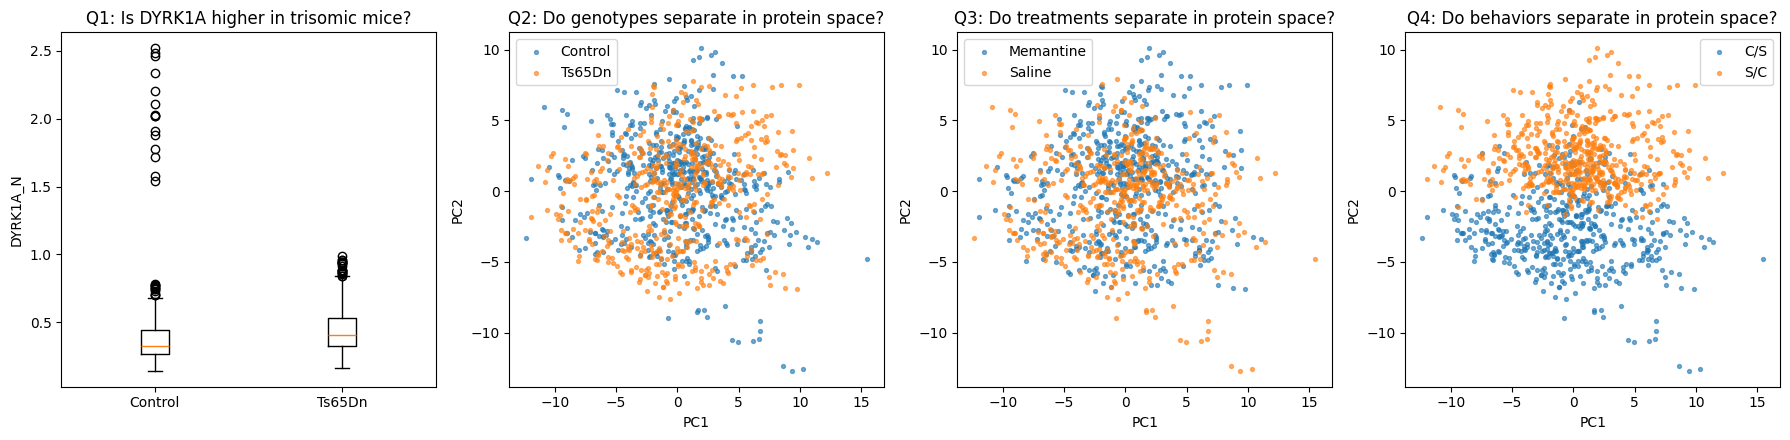

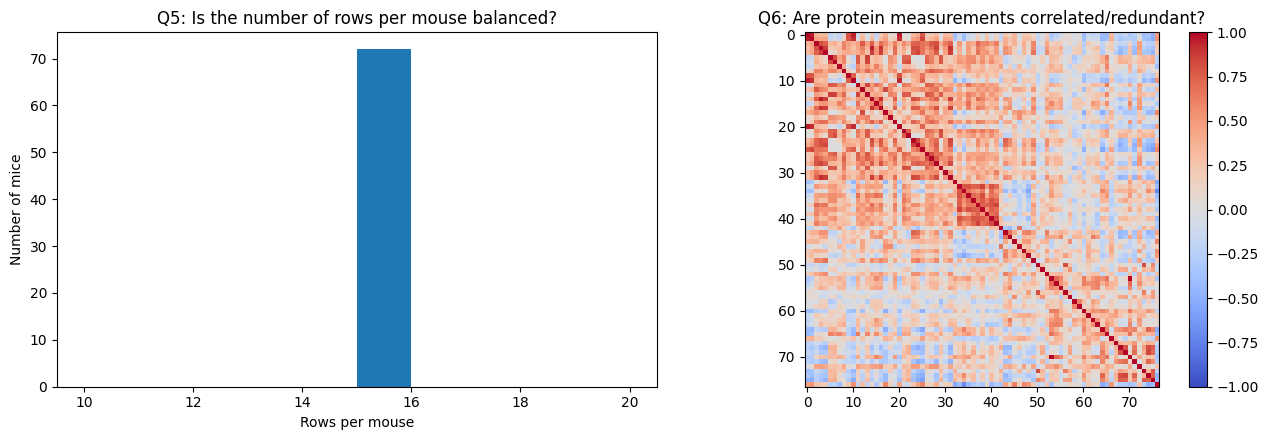

In [10]:
# Rows and unique mice per group
for col in ["Genotype", "Treatment", "Behavior", "class"]:
    print(f"\n{col}")
    print(pd.DataFrame({"rows": mice[col].value_counts(),
                        "unique_mice": mice.groupby(col)["mouse_id"].nunique()}))

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))

# Q1: DYRK1A by genotype
genotypes = mice["Genotype"].dropna().unique()
axes[0].boxplot([mice.loc[mice["Genotype"] == g, "DYRK1A_N"].dropna() for g in genotypes])
axes[0].set_xticklabels(genotypes)
axes[0].set_ylabel("DYRK1A_N")
axes[0].set_title("Q1: Is DYRK1A higher in trisomic mice?")

# Q2-Q4: one PCA (median imputation for visualization only), coloured three ways
X_vis = SimpleImputer(strategy="median").fit_transform(mice[protein_cols])
pcs = PCA(n_components=2).fit_transform(StandardScaler().fit_transform(X_vis))
panels = [("Genotype", "Q2: Do genotypes separate in protein space?"),
          ("Treatment", "Q3: Do treatments separate in protein space?"),
          ("Behavior", "Q4: Do behaviors separate in protein space?")]
for ax, (col, title) in zip(axes[1:], panels):
    for level in mice[col].dropna().unique():
        m = (mice[col] == level).to_numpy()
        ax.scatter(pcs[m, 0], pcs[m, 1], s=8, alpha=0.6, label=level)
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_title(title); ax.legend()
plt.tight_layout(); plt.show()

# Q5-Q6
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
cnt = mice.groupby("mouse_id").size()
axes[0].hist(cnt, bins=range(10, 21))
axes[0].set_xlabel("Rows per mouse"); axes[0].set_ylabel("Number of mice")
axes[0].set_title("Q5: Is the number of rows per mouse balanced?")
im = axes[1].imshow(mice[protein_cols].corr(), cmap="coolwarm", vmin=-1, vmax=1)
axes[1].set_title("Q6: Are protein measurements correlated/redundant?")
plt.colorbar(im, ax=axes[1])
plt.tight_layout(); plt.show()

1. DYRK1A_N by genotype — is DYRK1A higher in trisomic mice?** The gene lies in the triplicated region, so a dosage effect is expected. The median is slightly higher in Ts65Dn, but the distributions overlap heavily, and the Control group contains a set of high outliers (≈1.5–2.5); it is worth checking whether they come from a few mice. DYRK1A alone is not a clean separator.
2. PCA coloured by genotype -- no clear separation.
3. PCA coloured by treatment -- no visible separation.
4. PCA coloured by behavior -- C/S and S/C separate fairly clearly along PC2. The largest source of variation in protein space is the behavioral context, not genotype. This is a signal for genotype prediction.
5. every of the 72 mice has 15 rows.
6. mostly moderate positive correlations, with a visible block of strongly correlated proteins (around 33–41)

genotype classification is expected to be difficult, and design variables must be examined for confounding

### 3.3 Diagnostics

Report checks for:
- missingness in proteins and metadata: `proteins: 1,396 cells (1.68%), 49 of 77 proteins affected, worst BCL2_N 26%, H3MeK4_N 25%, BAD_N 20%, EGR1_N 19%, H3AcK18_N 17%, pCFOS_N 7%; metadata: none; structure analysed in section 2 (mouse-level, differs by genotype)` 
- duplicate rows or duplicate measurement identifiers: `none (0 duplicate rows, 0 duplicate MouseID)` 
- expected 15 measurements per mouse: `confirmed - all 72 mice have exactly 15 rows` 
- unusual categories or inconsistent labels: `none - 2 genotypes, 2 treatments, 2 behaviors, 8 classes, consistent spelling` 
- non-finite, negative, or implausible expression values: `no infinite values; one slightly negative value (-0.062), most likely a normalization/background artifact; kept because it is a single cell near zero (range -0.062 to 8.483)` 
- highly correlated or redundant protein variables: ` pairs with |r| > 0.95: ARC_N-pS6_N (identical, r = 1.0 -> pS6_N removed), DYRK1A_N-BRAF_N (0.960) and DYRK1A_N-ITSN1_N (0.960) (kept: plausible biological co-variation)` 
- predictors that are deterministic parts of the target: `class - the c-/t- prefix determines Genotype exactly (direct leakage, excluded); Treatment and Behavior do not determine Genotype`.

In [11]:
vals = mice[protein_cols]

print("Inf values:", int(np.isinf(vals.to_numpy(dtype=float)).sum()))
print("Negative values:", int((vals < 0).sum().sum()), "| min / max:", vals.min().min(), vals.max().max())
print("Constant features:", int((vals.var() == 0).sum()))
neg = vals.lt(0).stack()
for row, protein in neg[neg].index:
    print("Negative cell:", protein, "=", mice.loc[row, protein],
          "|", mice.loc[row, ["MouseID", "Genotype", "Treatment", "Behavior"]].to_dict())

corr = vals.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
high_pairs = upper.stack()
high_pairs = high_pairs[high_pairs > 0.95].sort_values(ascending=False)
print("\nProtein pairs with |r| > 0.95:", len(high_pairs))
print(high_pairs)
print("ARC_N and pS6_N identical incl. NaN pattern:", mice["ARC_N"].equals(mice["pS6_N"]))

print("\nclass vs Genotype:")
print(pd.crosstab(mice["class"], mice["Genotype"]))
for col in ["class", "Treatment", "Behavior"]:
    print(f"{col} determines Genotype:", bool((mice.groupby(col)["Genotype"].nunique() == 1).all()))

Inf values: 0
Negative values: 1 | min / max: -0.062007874 8.482553422
Constant features: 0
Negative cell: RRP1_N = -0.062007874 | {'MouseID': '365_14', 'Genotype': 'Control', 'Treatment': 'Memantine', 'Behavior': 'S/C'}

Protein pairs with |r| > 0.95: 3
ARC_N     pS6_N      1.000000
DYRK1A_N  BRAF_N     0.959578
          ITSN1_N    0.959512
dtype: float64
ARC_N and pS6_N identical incl. NaN pattern: True

class vs Genotype:
Genotype  Control  Ts65Dn
class                    
c-CS-m        150       0
c-CS-s        135       0
c-SC-m        150       0
c-SC-s        135       0
t-CS-m          0     135
t-CS-s          0     105
t-SC-m          0     135
t-SC-s          0     135
class determines Genotype: True
Treatment determines Genotype: False
Behavior determines Genotype: False


### 3.4 Preparation and feature roles

Selected supervised-learning question: predict the `Genotype` (Control vs Ts65Dn) of *new, unseen mice* from protein expression. `X` = protein columns, `y` = `Genotype`, `groups` = `mouse_id`.

Missing-value decision:
- Complete-row removal is too costly: it keeps only 447 of 810 training rows and, because missingness is mouse-level, it removes whole mice.
- Features with >5% missing values (6 proteins: `BAD_N`, `BCL2_N`, `pCFOS_N`, `H3AcK18_N`, `EGR1_N`, `H3MeK4_N`; threshold evaluated on training data only) are **removed**: they are missing for whole mice and unevenly across genotypes, so imputing them with one median would fabricate data for entire animals.
- The remaining sporadic gaps are **imputed with the median**, with the imputer fitted on the training data only and then applied to the test data.
- The redundant duplicate `pS6_N` (identical to `ARC_N`) is removed.

The fitting code must run *after* the split, so it follows in 3.5; the role table documenting every excluded variable is there too.

In [12]:
target_col = "Genotype"
X = mice[protein_cols].copy()
y = mice[target_col].copy()
groups = mice["mouse_id"].copy()
print("X:", X.shape, "| y:", y.shape, "| groups (mice):", groups.nunique())

X: (1080, 77) | y: (1080,) | groups (mice): 72


### 3.5 Split strategy
- Independent biological unit: `mouse`
- Grouping variable: `mouse_id`
- Split method: `StratifiedGroupKFold` (4 folds, `shuffle=True`, `random_state=100926`), first fold used as the test set -> 54 training mice (810 rows) and 18 test mice (270 rows)

**Population to generalize to:** new, unseen mice (not new measurements of mice already seen).

**Why a row-wise random split would be over-optimistic:** the 15 rows of a mouse are technical replicates of the same sample and are nearly identical, so a test row would have "twins" in the training set and the model could memorize individual mice instead of learning genotype biology.

**Stratification:** useful because there are only 72 mice and a random group split could give an unbalanced genotype ratio. It is compatible with grouping when `StratifiedGroupKFold` is used: it stratifies the *mice*, not the rows, so genotype proportions are preserved approximately rather than exactly (train 54/46, test 50/50 Control/Ts65Dn).

In [13]:
sgkf = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=RANDOM_STATE)
train_idx, test_idx = next(sgkf.split(X, y, groups=groups))

X_train_raw, X_test_raw = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
groups_train, groups_test = groups.iloc[train_idx], groups.iloc[test_idx]

print("Mouse overlap between train and test:", set(groups_train) & set(groups_test))
print("Train mice:", groups_train.nunique(), "| Test mice:", groups_test.nunique())
print("Rows per mouse in train/test:", groups_train.value_counts().unique(), groups_test.value_counts().unique())
print("\nTrain genotype share:\n", y_train.value_counts(normalize=True).round(2))
print("Test genotype share:\n", y_test.value_counts(normalize=True).round(2))

Mouse overlap between train and test: set()
Train mice: 54 | Test mice: 18
Rows per mouse in train/test: [15] [15]

Train genotype share:
 Genotype
Control    0.54
Ts65Dn     0.46
Name: proportion, dtype: float64
Test genotype share:
 Genotype
Control    0.5
Ts65Dn     0.5
Name: proportion, dtype: float64


In [ ]:
complete = X_train_raw.dropna()
print(f"Complete-row removal keeps {len(complete)} / {len(X_train_raw)} training rows "
      f"({groups_train.loc[complete.index].nunique()} / {groups_train.nunique()} mice)")

na_frac_train = X_train_raw.isna().mean()
print(f"Removing every feature with any NA would keep {int((na_frac_train == 0).sum())} / {len(protein_cols)} features")

dropped_na = na_frac_train[na_frac_train > 0.05].index.tolist()
redundant = ["pS6_N"]
keep_cols = [c for c in protein_cols if c not in dropped_na and c not in redundant]
print(f"Chosen rule: drop {len(dropped_na)} features with >5% NA {dropped_na} and redundant {redundant}; "
      f"keep {len(keep_cols)} features")

imputer = SimpleImputer(strategy="median")
X_train = pd.DataFrame(imputer.fit_transform(X_train_raw[keep_cols]),
                       columns=keep_cols, index=X_train_raw.index)
X_test = pd.DataFrame(imputer.transform(X_test_raw[keep_cols]),
                      columns=keep_cols, index=X_test_raw.index)
print("NA train/test:", X_train.isna().sum().sum(), X_test.isna().sum().sum())
print("X_train:", X_train.shape, "| X_test:", X_test.shape,
      "| y_train:", y_train.shape, "| y_test:", y_test.shape)

In [14]:
roles = pd.DataFrame([
    ("77 proteins (protein_cols)", "feature", "used (except those dropped due to missing values)"),
    ("MouseID", "measurement identifier", "excluded: unique record ID"),
    ("mouse_id", "group / biological unit", "excluded from X; used for GroupSplit"),
    ("Genotype", "target", "y"),
    ("class", "composite label", "excluded: contains genotype (leakage)"),
    ("Treatment", "experimental condition", "excluded: changes the research question, confounder"),
    ("Behavior", "experimental condition", "excluded: changes the research question, confounder"),
], columns=["column", "role", "decision"])
roles

,column,role,decision
0,77 proteins (protein_cols),feature,used (except those dropped due to missing values)
1,MouseID,measurement identifier,excluded: unique record ID
2,mouse_id,group / biological unit,excluded from X; used for GroupSplit
3,Genotype,target,y
4,class,composite label,excluded: contains genotype (leakage)
5,Treatment,experimental condition,"excluded: changes the research question, confo..."
6,Behavior,experimental condition,"excluded: changes the research question, confo..."


Complete-row removal would discard about 45% of the training rows (447 of 810) and whole mice; dropping every feature with any gap would remove a large share of the 77 proteins. The chosen compromise (drop the 6 high-missingness proteins and the duplicate `pS6_N`; median-impute the remaining sparse gaps using training statistics only) leaves **70 features**: `X_train` (810, 70), `X_test` (270, 70). Caveat: if the remaining gaps are not missing at random, median imputation may introduce systematic bias.

### 3.6 Confounding and distribution structure

Investigate associations between the target and:
- treatment 
- behavior 
- genotype 
- composite class 
- number of measurements per mouse.

All counts below are at the **mouse level** (one row per mouse) so that the 15 repeated rows do not inflate the numbers.

Genotype x Treatment (mice):
 Treatment  Memantine  Saline  All
Genotype                         
Control           20      18   38
Ts65Dn            18      16   34
All               38      34   72

Genotype x Behavior (mice):
 Behavior  C/S  S/C  All
Genotype               
Control    19   19   38
Ts65Dn     16   18   34
All        35   37   72

Composite class x Genotype (mice):
 Genotype  Control  Ts65Dn
cls                      
c-CS-m         10       0
c-CS-s          9       0
c-SC-m         10       0
c-SC-s          9       0
t-CS-m          0       9
t-CS-s          0       7
t-SC-m          0       9
t-SC-s          0       9

Rows per mouse by genotype:
           count  mean  std   min   25%   50%   75%   max
Genotype                                                
Control    38.0  15.0  0.0  15.0  15.0  15.0  15.0  15.0
Ts65Dn     34.0  15.0  0.0  15.0  15.0  15.0  15.0  15.0
Fisher exact, Genotype x Treatment: p = 1.000
Fisher exact, Genotype x Behavior: p = 0.818


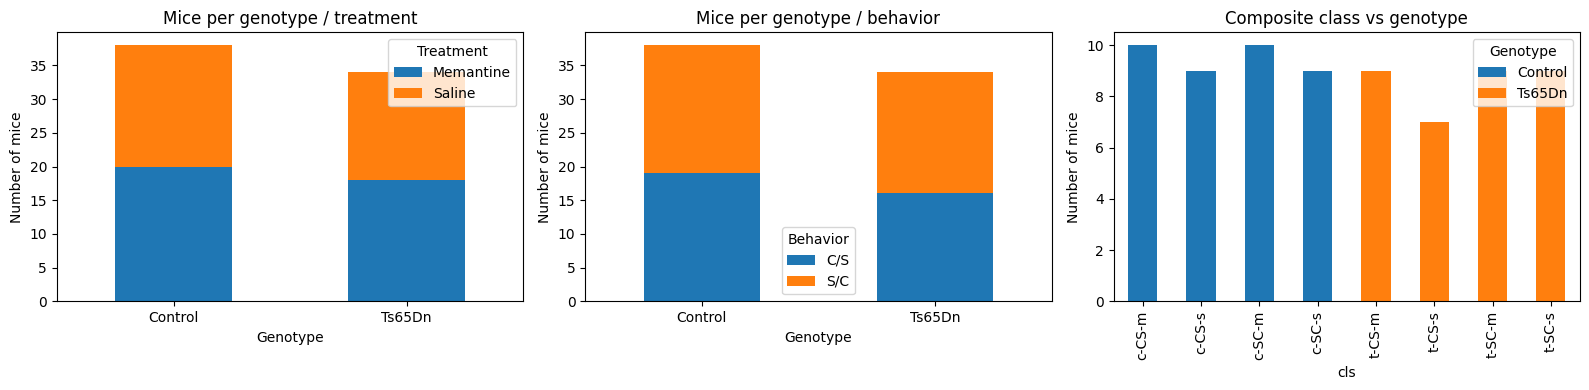

In [15]:
mouse_level = (mice.groupby("mouse_id")
               .agg(Genotype=("Genotype", "first"), Treatment=("Treatment", "first"),
                    Behavior=("Behavior", "first"), cls=("class", "first"),
                    n_rows=("MouseID", "size"))
               .reset_index())

print("Genotype x Treatment (mice):\n", pd.crosstab(mouse_level["Genotype"], mouse_level["Treatment"], margins=True))
print("\nGenotype x Behavior (mice):\n", pd.crosstab(mouse_level["Genotype"], mouse_level["Behavior"], margins=True))
print("\nComposite class x Genotype (mice):\n", pd.crosstab(mouse_level["cls"], mouse_level["Genotype"]))
print("\nRows per mouse by genotype:\n", mouse_level.groupby("Genotype")["n_rows"].describe())

for col in ["Treatment", "Behavior"]:
    odds, p = fisher_exact(pd.crosstab(mouse_level["Genotype"], mouse_level[col]))
    print(f"Fisher exact, Genotype x {col}: p = {p:.3f}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes[:2], ["Treatment", "Behavior"]):
    mouse_level.groupby(["Genotype", col]).size().unstack().plot(kind="bar", stacked=True, ax=ax)
    ax.set_ylabel("Number of mice"); ax.set_title(f"Mice per genotype / {col.lower()}")
    ax.tick_params(axis="x", rotation=0)
mouse_level.groupby(["cls", "Genotype"]).size().unstack(fill_value=0).plot(kind="bar", stacked=True, ax=axes[2])
axes[2].set_ylabel("Number of mice"); axes[2].set_title("Composite class vs genotype")
plt.tight_layout(); plt.show()

- Treatment and Behavior are approximately balanced across genotype at the mouse level (Fisher exact test: Genotype × Treatment p = 1.000, Genotype × Behavior p = 0.818). Neither can serve as a proxy for genotype, so there is no strong design confounding. With only 72 mice the tests have limited power, so this means "no evidence of imbalance", not proof of balance.
- Composite class: direct target leakage; the c-/t- prefix determines genotype exactly.
- Rows per mouse: exactly 15 for every mouse and genotype, so there is no recording-frequency bias.
- Behavior as a nuisance factor: it is the dominant axis of variation in the PCA (section B) although it is unrelated to genotype. A model must find the genotype signal underneath a larger design-related signal.
- Treatment × genotype interaction (distribution shift): memantine was used in the original study to rescue the trisomic phenotype, so protein profiles of treated Ts65Dn mice may move toward controls. Genotype is then not a homogeneous class, and results can depend on how treated and untreated mice fall into the folds.
- Missingness pattern: it is mouse-level and differs by genotype (section D), so any rule that keeps those proteins can exploit the missingness pattern instead of protein biology.
- Small number of mice: with 72 mice, performance is very sensitive to fold composition. The single split above gives a 50/50 genotype ratio in test and 54/46 in train; cross-validation (see the optional task) is needed for a stable estimate.
- Unobserved batch effects: processing days or batches are not recorded, so hidden batch effects cannot be excluded.

ML question. Predict the genotype (Control / Ts65Dn) of new, unseen mice from the expression profile of 70 proteins.

Biological unit. The mouse (72 mice, 15 technical measurements each).

Split strategy. `StratifiedGroupKFold` grouped by `mouse_id` (4 folds, first fold used; train = 54 mice, test = 18 mice). All 15 rows of a mouse stay in the same partition; genotype proportions are approximately preserved.

Why not a row-wise split. Rows of the same mouse are nearly identical, so a test row has "twins" in the training set and the model can memorize individual mice. In the optional experiment below, accuracy is 0.978 with a row-wise split versus 0.774 with the mouse-grouped split.

Main sources of bias, confounding or leakage.
1. `class` encodes genotype (direct leakage; excluded).
2. Behavior dominates the protein-space variation and treatment may interact with genotype; both are balanced across genotype but remain nuisance variation.
3. Missingness is mouse-level and differs by genotype.
4. Only 72 mice, so any single split gives a noisy estimate.

In [16]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

def eval_split(tr, te, label):
    clf = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                        LogisticRegression(max_iter=2000))
    clf.fit(X.iloc[tr], y.iloc[tr])
    print(f"{label}: accuracy = {clf.score(X.iloc[te], y.iloc[te]):.3f}")

tr_r, te_r = train_test_split(np.arange(len(X)), test_size=0.25,
                              stratify=y, random_state=RANDOM_STATE)
eval_split(tr_r, te_r, "Row-wise split  ")
eval_split(train_idx, test_idx, "Mouse-grouped    ")

Row-wise split  : accuracy = 0.978
Mouse-grouped    : accuracy = 0.774


A row-wise split evaluates whether the model can recognize new measurements from a mouse it has already seen, whereas a grouped split evaluates whether it generalizes to entirely new mice. Only the latter answers the actual biological question.

Predicting Genotype is biologically cleaner because it isolates a single biological factor. class conflates genotype, behavior, and treatment; moreover, it must be excluded when predicting Genotype to avoid target leakage.

ai usage report: i asked copilot to polish texts from grammatical side and it is also enabled for code suggestions in my vs code